# Session 1 – Current Control of a PMSM: PI, MPC and Reinforcement Learning

In this session we control the **currents of a Permanent Magnet Synchronous Machine (PMSM)** with three very different
controllers and compare them on the same task:

| Controller | Needs a model? | How it decides the voltage |
|---|---|---|
| **PI** (proportional–integral) | No (but the model helps tuning) | A fixed formula on the tracking error |
| **MPC** (model predictive control) | **Yes** | Solves an optimisation problem at every time step |
| **DDPG** (reinforcement learning) | No | A neural network learned by trial and error |

### Learning goals
After this session you should be able to:
1. Explain the dq-model of a PMSM and how it becomes a discrete-time simulation.
2. Explain the Gymnasium interface (`reset`, `step`, observations, actions, rewards).
3. Explain why feedback is needed and how a PI controller provides it.
4. Explain what MPC optimises and what its weights do.
5. Explain how an RL agent sees the same control problem, and compare all three controllers.

### How to use this notebook
Run the cells from top to bottom (`Shift + Enter`). The code is complete. Each section explains what the next cells do,
and the **questions** are for discussion in class.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
import ipywidgets as widgets
from IPython.display import display

from environment import EnvPMSM          # The motor simulation (a Gymnasium environment)
from controllers import MPCController    # MPC implementation
from utils import *                      # Simulation and plotting helpers (run_simulation, columns, ...)
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

# Register the environment so it can be created with gym.make("EnvPMSM")
gym.register(
    id="EnvPMSM",
    entry_point=EnvPMSM,
)

figsize = (10, 6)

---
# 1. The control problem

A complete drive consists of the motor, an inverter, pulse width modulation (PWM), dq–abc transformations,
measurements, references, and a controller that makes the measured currents follow the references:

<div style="text-align: center">
  <img src="./images/General_Control_Scheme.png" alt="Control Scheme" />
</div>

In this session we use a **simplified** version: we work directly in the dq-frame and assume that the inverter
produces exactly the voltage the controller asks for. The inverter, PWM and dq–abc transformations are left out.

<div style="text-align: center">
  <img src="./images/General_Control_Scheme_dq.png" alt="Control Scheme" />
</div>

The **"Controller"** block is what we will design: it receives the reference currents $I_{dq,\mathrm{ref}}$ and the
measured currents $I_{dq}$, and outputs the voltages $V_{dq}$.

---
# 2. The PMSM model

### 2.1 Voltage equations
In the dq-frame, which rotates with the rotor at electrical speed $\omega_e$, the stator voltages are
$$
\begin{align*}
V_d &= RI_d + \dfrac{d\lambda_d}{dt} - \omega_e\lambda_q,\\
V_q &= RI_q + \dfrac{d\lambda_q}{dt} + \omega_e\lambda_d,
\end{align*}
$$
where $R$ is the stator resistance, $V_{dq}$ and $I_{dq}$ are the phase voltages and currents in dq-coordinates,
and the flux linkages are
$$
\begin{align*}
\lambda_d &= L_dI_d + \lambda_{\mathrm{PM}},\\
\lambda_q &= L_qI_q,
\end{align*}
$$
with $L_{d}, L_q$ the dq-inductances and $\lambda_{PM}$ the flux linkage of the permanent magnets.
Substituting the flux linkages gives
$$
\begin{align*}
V_d &= RI_d + L_d\dfrac{dI_d}{dt} - \omega_eL_qI_q,\\
V_q &= RI_q + L_q\dfrac{dI_q}{dt} + \omega_e(L_dI_d + \lambda_{\mathrm{PM}}).
\end{align*}
$$

Each term has a physical meaning:

| Term | Meaning |
|---|---|
| $RI_d$, $RI_q$ | Voltage drop over the stator resistance |
| $L_d\,dI_d/dt$, $L_q\,dI_q/dt$ | Voltage needed to **change** the current (the inductance resists change) |
| $-\omega_eL_qI_q$, $\omega_eL_dI_d$ | **Cross-coupling**: the d-axis current affects the q-axis voltage and vice versa |
| $\omega_e\lambda_{PM}$ | **Back-EMF** of the magnets: a disturbance that grows with speed |

### 2.2 State-space form
Solving for the derivatives gives a linear state-space model $\dot{x} = A_cx + B_cu + W_c$ with
state $x = [I_d,\ I_q]^T$ (the currents) and input $u = [V_d,\ V_q]^T$ (the voltages):
$$
\begin{bmatrix} \dfrac{dI_d}{dt} \\[6pt] \dfrac{dI_q}{dt} \end{bmatrix} =
\underbrace{\begin{bmatrix} -\frac{R}{L_d} & \frac{\omega_e L_q}{L_d}\\[6pt] -\frac{\omega_e L_d}{L_q} & -\frac{R}{L_q} \end{bmatrix}}_{A_c}
\begin{bmatrix} I_d \\[6pt] I_q \end{bmatrix} +
\underbrace{\begin{bmatrix} \frac{1}{L_d} & 0\\[6pt] 0 & \frac{1}{L_q} \end{bmatrix}}_{B_c}
\begin{bmatrix} V_d \\[6pt] V_q \end{bmatrix} +
\underbrace{\begin{bmatrix} 0 \\[6pt] -\frac{\omega_e\lambda_{PM}}{L_q} \end{bmatrix}}_{W_c}
$$

- The diagonal of $A_c$ (the $-R/L$ terms) makes the currents decay on their own.
- The off-diagonal terms are the cross-coupling: they make the problem **multivariable**.
- $W_c$ does not depend on the state or the input. It is a constant disturbance at constant speed.

### 2.3 Discrete time
A digital controller acts every $\Delta t$ seconds. The environment converts the continuous model into a discrete one with a
**zero-order hold** (the voltage is kept constant during each sampling period):
$$
x_{k+1} = A_d\,x_k + B_d\,u_k + w_d .
$$
This is what `scipy.signal.cont2discrete(..., method='zoh')` does inside `environment.py`. Every call to
`env.step(action)` applies this equation once.

---
# 3. The environment

The motor is implemented as a [Gymnasium](https://gymnasium.farama.org/) environment. This is the standard interface used
in RL, and it works for any controller. It has three methods:

| Method | What it does |
|---|---|
| `__init__` | Stores the parameters, builds $A_d, B_d, w_d$ and defines the action and observation spaces |
| `reset()` | Starts a new episode: currents back to $0$, returns the first observation |
| `step(action)` | Applies one voltage for $\Delta t$ and returns `(observation, reward, terminated, truncated, info)` |

**Normalisation.** Neural networks learn best with values around $[-1, 1]$, so the environment works with normalised values:
- **Action** $a \in [-1, 1]^2$ → voltage $V_{dq} = a \cdot V_{DC}/2$ (so $\pm 600$ V).
- **Observation** $o = I_{dq} / I_{\max}$ (so $\pm 1$ corresponds to $\pm 200$ A).

**Reward.** The environment already computes the reward that the RL agent will use later:
$$
r_k = -\left(\frac{|I_{d,k} - I_{d,\mathrm{ref}}|}{I_{\max}} + \frac{|I_{q,k} - I_{q,\mathrm{ref}}|}{I_{\max}}\right)
$$
The reward is $0$ when the currents are exactly on reference, and negative otherwise.

### Parameters
The sampling frequency is $10$ kHz, an episode lasts $200$ steps ($20$ ms), the current is limited to $200$ A, the DC-bus voltage
is $1200$ V, and with sinusoidal PWM (SPWM) the voltage is limited to $V_{DC}/2 = 600$ V.

In [2]:
sys_params = {
    "dt": 1 / 10e3,             # Simulation step time [s]
    "r": 29.0808e-3,            # Phase Stator Resistance [Ohm]
    "ld": 0.91e-3,              # D-axis Inductance [H]
    "lq": 1.17e-3,              # Q-axis Inductance [H]
    "lambda_PM": 0.172312604,   # Flux-linkage due to permanent magnets [Wb]
    "we": 50*2*np.pi,           # Electrical speed [rad/s]
    "vdc": 1200,                # DC bus voltage [V]
    "sim_steps": 200,           # Simulation steps per episode
    "i_max": 200,               # Maximum current [A]
    "id_ref": -10.0,            # Reference d-axis current [A]
    "iq_ref": 100.0             # Reference q-axis current [A]
}
sim_plot_steps = 20             # Number of steps shown in the plots

### Getting a feeling for the numbers
The next cell computes three numbers that we will use throughout the session:
- the **electrical time constants** $\tau_d = L_d/R$ and $\tau_q = L_q/R$: how fast the currents respond,
- the **back-EMF** $\omega_e\lambda_{PM}$: the voltage the magnets induce at this speed,
- how many **simulation steps** fit in one time constant.

In [3]:
tau_d = sys_params["ld"] / sys_params["r"]
tau_q = sys_params["lq"] / sys_params["r"]
back_emf = sys_params["we"] * sys_params["lambda_PM"]
steps_per_tau_q = tau_q / sys_params["dt"]

print(f"tau_d = {1e3*tau_d:.1f} ms, tau_q = {1e3*tau_q:.1f} ms")
print(f"Back-EMF = {back_emf:.1f} V")
print(f"Steps per tau_q = {steps_per_tau_q:.0f}   (one episode = {sys_params['sim_steps']} steps)")

tau_d = 31.3 ms, tau_q = 40.2 ms
Back-EMF = 54.1 V
Steps per tau_q = 402   (one episode = 200 steps)


An episode lasts only $200$ steps ($20$ ms), which is about **half** a time constant. Keep this in mind: it is short
compared to how fast the motor responds on its own.

### Create and explore the environment
The next cell creates the environment and prints its action and observation spaces and the discrete matrices
$A_d$, $B_d$ and $w_d$. `gym.make` wraps the environment in a few safety layers; `env.unwrapped` gives the original
object, so we can read attributes such as `ad`, `bd` and `i_max`.

In [4]:
# Create environment instance
env = gym.make("EnvPMSM", sys_params=sys_params)
base_env = env.unwrapped

print("Action space:     ", env.action_space)
print("Observation space:", env.observation_space)
print("\nA_d =\n", base_env.ad)
print("\nB_d =\n", base_env.bd)
print("\nw_d =", base_env.wd)

Action space:      Box(-1.0, 1.0, (2,), float32)
Observation space: Box(-1.0, 1.0, (2,), float32)

A_d =
 [[ 0.99631743  0.04027071]
 [-0.02436129  0.99702545]]

B_d =
 [[ 0.10969667  0.00172274]
 [-0.00133991  0.08534992]]

w_d = [-0.09325827 -4.62029873]


Every controller in this course interacts with the motor through the same loop: `reset()` once, then `step(action)`
repeatedly. The next cell applies $60$ V on the q-axis for three steps and prints the currents and the reward.

In [5]:
obs, info = env.reset()
print("Initial observation (normalised currents):", obs)

action = np.array([0.0, 0.1], dtype=np.float32)   # 0 V on d, 0.1*600 = 60 V on q
for k in range(3):
    obs, reward, terminated, truncated, info = env.step(action)
    print(f"step {k}: I_dq = {obs * base_env.i_max} A,  reward = {reward:.3f}")

Initial observation (normalised currents): [0. 0.]
step 0: I_dq = [0.0101063 0.5006967] A,  reward = -0.550
step 1: I_dq = [0.04033878 0.9996578 ] A,  reward = -0.548
step 2: I_dq = [0.09055346 1.4963983 ] A,  reward = -0.545


### Helper functions
The next cell defines two small helpers used in the experiments below:
- `run_open_loop` applies the **same** action at every step (no feedback) and returns the currents,
- `plot_currents` plots the currents against their references.

In [6]:
def run_open_loop(env, action, n_steps):
    "Apply the same action for n_steps steps (no feedback). Returns the currents [A], shape (steps + 1, 2)."
    obs, _ = env.reset()
    currents = [obs * env.unwrapped.i_max]
    for _ in range(n_steps):
        obs, _, terminated, truncated, _ = env.step(action)
        currents.append(obs * env.unwrapped.i_max)
        if terminated or truncated:
            break
    return np.array(currents)


def plot_currents(currents, title):
    "Plot I_d and I_q [A] against time [ms], together with their references."
    t_ms = 1e3 * sys_params["dt"] * np.arange(len(currents))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t_ms, currents[:, 0], label="$I_d$")
    ax.plot(t_ms, currents[:, 1], label="$I_q$")
    ax.axhline(sys_params["id_ref"], ls="--", c="C0", alpha=.5, label="$I_{d,ref}$")
    ax.axhline(sys_params["iq_ref"], ls="--", c="C1", alpha=.5, label="$I_{q,ref}$")
    ax.set_xlabel("Time [ms]"); ax.set_ylabel("Current [A]"); ax.grid(True); ax.legend()
    ax.set_title(title)
    plt.show()

### Open-loop control: can we just compute the right voltage?
If we know the model perfectly, we can compute the constant voltage that holds the currents at their reference in
steady state. In steady state $x_{k+1} = x_k = x_{\mathrm{ref}}$, so
$$
x_{\mathrm{ref}} = A_d x_{\mathrm{ref}} + B_d u_{ss} + w_d
\quad\Rightarrow\quad
u_{ss} = B_d^{-1}\big((I - A_d)\,x_{\mathrm{ref}} - w_d\big).
$$
The next cell computes $u_{ss}$, applies it as a constant action for one episode, and plots the result.

Steady-state voltage u_ss = [-37.   54.2] V


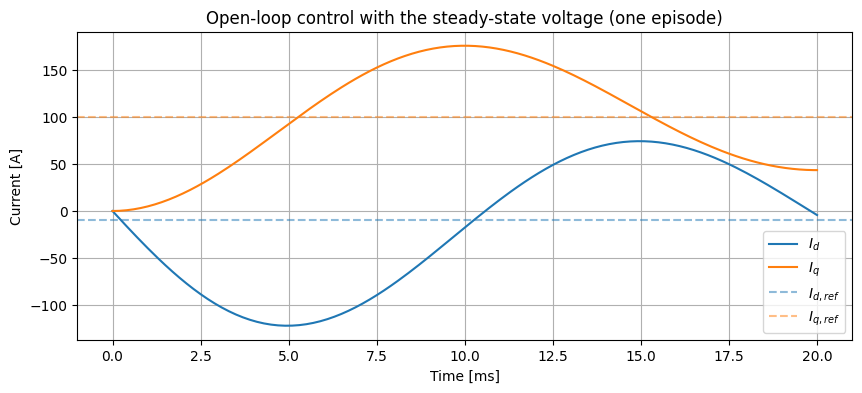

In [7]:
x_ref = np.array([sys_params["id_ref"], sys_params["iq_ref"]])

# Steady-state voltage [V] and the corresponding normalised action
u_ss = np.linalg.solve(base_env.bd, (np.eye(2) - base_env.ad) @ x_ref - base_env.wd)
action_ss = (u_ss / base_env.vdq_max).astype(np.float32)
print("Steady-state voltage u_ss =", np.round(u_ss, 1), "V")

currents = run_open_loop(env, action_ss, sys_params["sim_steps"])
plot_currents(currents, "Open-loop control with the steady-state voltage (one episode)")

The next cell repeats the same experiment for $200$ ms ($10$ episodes) to see where the currents end up.

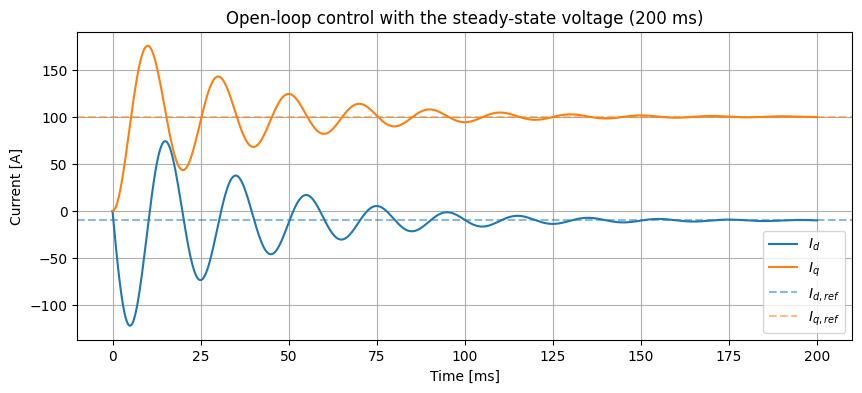

In [8]:
long_env = gym.make("EnvPMSM", sys_params=dict(sys_params, sim_steps=2000))
currents = run_open_loop(long_env, action_ss, 2000)
plot_currents(currents, "Open-loop control with the steady-state voltage (200 ms)")

In practice the model is never exact. The next cell computes $u_{ss}$ with a model whose resistance and inductances are
**10 % wrong**, applies it to the real motor for $200$ ms, and compares the final currents with the exact-model case.

In [9]:
# Open-loop voltage computed with a wrong model (+10% on R, L_d, L_q)
error = 0.1
wrong_params = dict(sys_params, r=(1 + error)*sys_params["r"], ld=(1 + error)*sys_params["ld"], lq=(1 + error)*sys_params["lq"])
wrong_env = gym.make("EnvPMSM", sys_params=wrong_params).unwrapped
u_wrong = np.linalg.solve(wrong_env.bd, (np.eye(2) - wrong_env.ad) @ x_ref - wrong_env.wd)

# Apply both voltages to the TRUE motor for 200 ms
for name, u in [("exact model", u_ss), ("wrong model", u_wrong)]:
    i_end = run_open_loop(long_env, (u / base_env.vdq_max).astype(np.float32), 2000)[-1]
    print(f"{name:12s}: I_dq after 200 ms = {np.round(i_end, 1)} A   (reference {x_ref})")

exact model : I_dq after 200 ms = [-10.   99.7] A   (reference [-10. 100.])
wrong model : I_dq after 200 ms = [-11.  109.6] A   (reference [-10. 100.])


**Questions**
1. Why do the currents not reach the reference within one episode, even with the exact voltage?
2. What happens to the final currents with the wrong model? Why do we need **feedback**?

---
# 4. Performance metrics

To compare controllers objectively we need numbers, not only plots. The next cell defines a `Metrics` class that
`run_simulation` uses to fill the results table. $T_f$ is the last time step of the simulation:

| Name | Function | Equation | What it tells you |
|---|---|---|---|
| Steady-state relative error | `error_r` | $\displaystyle\frac{1}{5}\sum_{k=T_f-5}^{T_f} \frac{\lvert I_{d,k} - I_{d,\mathrm{ref}}\rvert}{\lvert I_{d,\mathrm{ref}}\rvert} + \frac{\lvert I_{q,k} - I_{q,\mathrm{ref}}\rvert}{\lvert I_{q,\mathrm{ref}}\rvert}$ | Final accuracy, relative |
| Steady-state absolute error | `error` | $\displaystyle\frac{1}{5}\sum_{k=T_f-5}^{T_f} \lvert I_{d,k} - I_{d,\mathrm{ref}}\rvert + \lvert I_{q,k} - I_{q,\mathrm{ref}}\rvert$ | Final accuracy, in A |
| Sum of squared errors | `sse` | $\displaystyle\sum_{k=0}^{T_f} (I_{d,k} - I_{d,\mathrm{ref}})^2 + (I_{q,k} - I_{q,\mathrm{ref}})^2$ | Accuracy over the whole transient |
| Control energy | `control_energy` | $\displaystyle\Delta t\sum_{k=0}^{T_f} V_{d,k}^2 + V_{q,k}^2$ | How much effort the controller uses |
| Settling time | `settling_time` | Time after which the signal stays stable | Speed of the response |
| Overshoot | `overshoot` | Peak beyond the reference, in % of the reference | Aggressiveness |
| Undershoot | `undershoot` | Largest move in the wrong direction, in % of the reference | Wrong-direction response |
| Computation time | `computation_time` | Time to compute one action | Can it run in real time at 10 kHz (100 µs)? |

In [10]:
class Metrics:
    def __init__(self, idq_ref, dt):
        self.dt = dt                        # Simulation step time [s]
        self.idq_ref = np.array(idq_ref)    # Reference currents in dq-axis [A], shape (2,)

        # Helpers for matrix-vector subtraction and division (vector applied to every column)
        self.mv_sub = lambda matrix, vector: (matrix.transpose() - vector).transpose()
        self.mv_div = lambda matrix, vector: (matrix.transpose() / vector).transpose()

    def error_r(self, idq):
        # 1/5 * sum(|I_dq(Tf-5:Tf) - I_dq_ref| / |I_dq_ref|)
        return 1/5*np.sum(self.mv_div(np.abs(self.mv_sub(idq[:, -5:], self.idq_ref)), np.abs(self.idq_ref)))

    def error(self, idq):
        # 1/5 * sum(|I_dq(Tf-5:Tf) - I_dq_ref|)
        return 1/5*np.sum(np.abs(self.mv_sub(idq[:, -5:], self.idq_ref)))

    def sse(self, idq):
        # sum((I_dq(t) - I_dq_ref)^2)
        return np.sum(self.mv_sub(idq, self.idq_ref)**2)

    def control_energy(self, vdq):
        # dt * sum(V_dq(t)^2)
        return self.dt * np.sum(vdq**2)

    def settling_time(self, time_vec, signal, stability_threshold=0.05, window_percent=10):
        n_channels = signal.shape[0]
        settling_times = []
        viz_data_list = []

        # Iterate over each channel (row) in the signal array
        for i in range(n_channels):
            current_signal = signal[i, :]
            s = pd.Series(current_signal)

            # Moving-window size
            window_size = max(int((window_percent / 100) * len(s)), 2)

            # Moving statistics (edges filled with the nearest valid value)
            moving_avg = s.rolling(window=window_size, center=True).mean().bfill().ffill()
            moving_std = s.rolling(window=window_size, center=True).std().bfill().ffill()

            # Relative rate of change
            signal_abs_mean = np.mean(np.abs(current_signal))
            if signal_abs_mean < 1e-9:      # Prevent division by zero
                signal_abs_mean = 1.0
            avg_rate_of_change = np.abs(np.diff(moving_avg) / signal_abs_mean)
            std_rate_of_change = np.abs(np.diff(moving_std) / signal_abs_mean)

            # The signal is settled after the last "unstable" sample
            is_unstable = (avg_rate_of_change > stability_threshold) | \
                          (std_rate_of_change > stability_threshold)
            unstable_indices = np.where(is_unstable)[0]
            settling_index = window_size if len(unstable_indices) == 0 else unstable_indices[-1] + 1

            settling_times.append(None if settling_index >= len(time_vec) else time_vec[settling_index])
            viz_data_list.append({
                'moving_avg': moving_avg.to_numpy(),
                'moving_std': moving_std.to_numpy(),
                'settling_index': settling_index
            })

        return np.array(settling_times), viz_data_list

    def overshoot(self, idq):
        # Peak beyond the reference, in the direction of the reference (works for negative references too)
        result = []
        for i, iref in zip(idq, self.idq_ref):
            peak = np.max(np.sign(iref) * i)
            result.append(100*(peak - np.abs(iref))/np.abs(iref) if peak > np.abs(iref) else np.nan)
        return np.array(result)

    def undershoot(self, idq):
        # Largest move in the WRONG direction (opposite to the reference), relative to the initial value
        result = []
        for i, iref in zip(idq, self.idq_ref):
            dip = np.max(-np.sign(iref) * (i - i[0]))
            result.append(100*dip/np.abs(iref) if dip > 0 else np.nan)
        return np.array(result)

    def computation_time(self, controller, controller_inputs):
        start_time = time.perf_counter()
        action = controller(**controller_inputs)
        elapsed_time_ms = 1e3*(time.perf_counter() - start_time)
        return action, elapsed_time_ms

In [11]:
# Metrics object used by all simulations below
metrics = Metrics(np.array([base_env.id_ref, base_env.iq_ref]), base_env.dt)

---
# 5. PI controller

### 5.1 Control law
A PI controller computes the voltage from the **tracking error**
$$
e_{I_{dq}}(t) = I_{dq,\mathrm{ref}}(t) - I_{dq}(t)
$$
as
$$
V_{dq}(t) = \underbrace{K_p\,e_{I_{dq}}(t)}_{\text{reacts to the present error}} + \underbrace{K_i\int_0^t e_{I_{dq}}(\tau)\, d\tau}_{\text{removes the remaining error}}.
$$

- The **proportional** part pushes harder the larger the error is. On its own it leaves a steady-state error, because a
  non-zero voltage is needed to hold the current, and $K_p e$ only gives a non-zero voltage while $e \neq 0$.
- The **integral** part keeps growing as long as there is any error, until the error is exactly zero.

### 5.2 Discrete implementation
On a computer the integral becomes a sum (a Riemann approximation):
$$
V_{dq}(k) = K_p\,e_{I_{dq}}(k) + K_i\,\Delta t\sum_{j=0}^{k} e_{I_{dq}}(j).
$$
In code we do not store all past errors. We keep a **running sum** (`self.error_sum`) and update it every step:
```
error_sum ← error_sum + error · Δt
```
Finally, the voltage is limited to what the inverter can deliver ($\pm 600$ V) with `np.clip`.
The next cell implements exactly this.

In [12]:
class PIController:
    def __init__(self, Kp, Ki, Ts, umax, anti_windup=True):
        self.Kp = Kp                    # Proportional gain
        self.Ki = Ki                    # Integral gain
        self.Ts = Ts                    # Sampling time [s]
        self.umax = umax                # Maximum input [V]
        self.anti_windup = anti_windup  # Enable/disable anti-windup
        self.error_sum = np.zeros(2)    # Accumulated error (the "integral")

    def reset(self):
        # Reset error accumulation (call at the start of every episode)
        self.error_sum = np.zeros(2)

    def control(self, reference, measured):
        # Tracking error e = r - y
        error = reference - measured

        # Running sum of the error: approximates the integral
        error_sum_new = self.error_sum + error * self.Ts

        # Control law: u = Kp*e + Ki*Ts*Σe
        u_unsat = self.Kp * error + self.Ki * self.error_sum

        if self.anti_windup:
            # Freeze the integral on an axis that is saturated AND whose error
            # would push it further into saturation (conditional integration)
            saturated = np.abs(u_unsat) > self.umax
            pushing_out = np.sign(error) == np.sign(u_unsat)
            freeze = saturated & pushing_out
            error_sum_new = np.where(freeze, self.error_sum, error_sum_new)
            u_unsat = self.Kp * error + self.Ki * error_sum_new

        self.error_sum = error_sum_new

        # Respect the voltage limits of the inverter
        return np.clip(u_unsat, -self.umax, self.umax)

### 5.3 Simulate the PI controller
`run_simulation` (from `utils.py`) runs one episode with any controller and returns the metrics. The next cell wraps it
for the PI controller, so we can change $K_p$ and $K_i$ with sliders and see the effect immediately.

In [13]:
def show_table(table_data, index):
    "Display the metrics returned by run_simulation as a formatted table."
    table = pd.DataFrame(table_data, index=index, columns=columns).fillna("")
    table = table.style \
        .format(precision=3, thousands=".", decimal=",") \
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "center")]},
            {"selector": "td", "props": [("text-align", "center")]}
        ])
    display(table)


def run_pi_controller_sim(Kp, Ki, envs, anti_windup=True, figsize=(10, 5), show=True):
    controller = PIController(Kp=Kp, Ki=Ki, Ts=base_env.dt, umax=base_env.vdc/2, anti_windup=anti_windup)
    table_data = run_simulation(envs=envs, controller=controller, controller_type="PI", metrics=metrics,
                                figsize=figsize, sim_steps=sim_plot_steps, plot=show)
    if show:
        show_table(table_data, ["PI Controller"])
    return table_data

The initial gains in the next cell were precomputed for this motor. Run it, then move the sliders.

In [14]:
# Initial gains for the controller
Kp = 3.9932
Ki = Kp*(1-0.8776)/base_env.dt

# Sliders
Kp_slider = widgets.FloatSlider(value=Kp, min=0, max=20, step=0.1, description='Kp')
Ki_slider = widgets.FloatSlider(value=Ki, min=0, max=100_000, step=1, description='Ki')
# Checkbox for anti-windup
aw_checkbox = widgets.Checkbox(value=True, description='Anti-windup')

ui = widgets.HBox([Kp_slider, Ki_slider, aw_checkbox])
out = widgets.interactive_output(
    run_pi_controller_sim,
    {
        'Kp': Kp_slider,
        'Ki': Ki_slider,
        'envs': widgets.fixed(env),
        'anti_windup': aw_checkbox,
        'figsize': widgets.fixed(figsize)
    }
)
display(ui, out)

Output()

**Questions – PI tuning**
1. Make $K_i$ very large. What do you see?
2. When the output is clipped at $\pm 600$ V, the error sum keeps growing (**integrator windup**). Why is that a problem?
3. Both axes use the same gains, but $L_d \neq L_q$. Does that matter?

---
# 6. Model Predictive Control (MPC)
For a detailed explanation see: [Model Predictive Control System Design and Implementation Using MATLAB](https://link.springer.com/book/10.1007/978-1-84882-331-0).
The derivation of the matrices is in `controllers.ipynb`.

### 6.1 Key idea
MPC uses the model $x_{k+1} = A_dx_k + B_du_k + w_d$ to **look ahead**. At every control step it:
1. **Predicts** how the currents will evolve over the next $N$ steps (the *prediction horizon*) for a candidate sequence of inputs.
2. **Optimises**: it finds the input sequence that minimises a cost function (tracking error + control effort).
3. **Applies only the first input** of that sequence.
4. **Repeats** at the next step with the new measurement. This is called the *receding horizon*.

Step 4 is what makes MPC a **feedback** controller: model errors are corrected because the optimisation starts again
from the measured state at every step.

<div style="text-align: center">
  <img src="./images/MPC_scheme_basic.svg" alt="MPC scheme" />
</div>

### 6.2 Cost function
$$
\min_{\Delta u}\; \underbrace{(y_N-r)^TP(y_N-r)}_{\text{final error}} \;+\; \sum_{k=0}^{N-1}\underbrace{(y_k-r)^TQ(y_k-r)}_{\text{tracking error}} \;+\; \sum_{k=0}^{N-1}\underbrace{\Delta u_k^TR\,\Delta u_k}_{\text{input changes}}
$$
where $y$ are the predicted currents, $r$ the references and $\Delta u_k = u_k - u_{k-1}$ the **change** in voltage.

| Weight | Penalises | Larger value means... |
|---|---|---|
| $Q$ | Tracking error during the horizon | faster, more aggressive tracking |
| $P$ | Error at the end of the horizon (as a multiple of $Q$) | more emphasis on reaching the reference |
| $R$ | Changes in voltage $\Delta u$ | smoother but slower voltages |

In the code, $P$ is a **multiplier on $Q$**: the terminal weight is $P \cdot Q$.
Only the **ratios** between the weights matter: multiplying $Q$ and $R$ by 10 gives the same controller.

### 6.3 Why $\Delta u$ instead of $u$?
The implementation uses a model with an **embedded integrator**: the optimisation variable is the *change* of the input.
When the optimiser chooses $\Delta u = 0$, the voltage stays where it is instead of going back to zero. This gives
**zero steady-state error**, just like the integral part of the PI controller.

### 6.4 Quadratic programme
Because the model is linear and the cost is quadratic, the problem becomes a **quadratic programme (QP)**:
$$
\min_{\Delta U}\; \tfrac{1}{2}\Delta U^T G\, \Delta U + q^T\Delta U \quad \text{s.t.}\quad M\,\Delta U \le n,
$$
which is solved at every step with `qpsolvers` (OSQP solver). The constraints $M\Delta U \le n$ can encode voltage limits,
limits on voltage changes, and current limits.

The next two cells run the MPC with sliders for $Q$, $P$, $R$ and the horizon $N$.

In [15]:
def run_mpc_controller_sim(Q, P, R, N, envs, figsize=(10, 5), show=True):
    controller = MPCController(base_env, Q, P, R, N=N)
    table_data = run_simulation(envs=envs, controller=controller, controller_type="MPC", metrics=metrics,
                                figsize=figsize, sim_steps=sim_plot_steps, plot=show)
    if show:
        show_table(table_data, ["MPC"])
    return table_data

In [16]:
# Initial weights
Q = 100     # y - r     (tracking error)
P = 10      # y_N - r_N (final tracking error, as a multiple of Q)
R = 1       # Δu        (input changes)
N = 5       # Prediction horizon [steps]

Q_slider = widgets.FloatSlider(value=Q, min=0, max=200, step=1, description='Q')
P_slider = widgets.FloatSlider(value=P, min=0, max=2000, step=1, description='P')
R_slider = widgets.FloatSlider(value=R, min=0, max=200, step=1, description='R')
N_slider = widgets.IntSlider(value=N, min=1, max=30, step=1, description='N')

ui = widgets.HBox([Q_slider, P_slider, R_slider, N_slider])
out = widgets.interactive_output(
    run_mpc_controller_sim,
    {
        'Q': Q_slider,
        'P': P_slider,
        'R': R_slider,
        'N': N_slider,
        'envs': widgets.fixed(env),
        'figsize': widgets.fixed(figsize)
    }
)
display(ui, out)

Output()

**Questions – MPC**
1. Increase $R$ with $Q$ fixed. How do the voltages and the settling time change?
2. Compare $Q = 1, R = 1$ with $Q = 100, R = 100$. Is there a difference? Why (not)?
3. Increase $N$. How do the response and the **computation time** change? Is MPC fast enough for a $100\,\mu\text{s}$ control period?
4. MPC relies on $A_d$, $B_d$ and $w_d$. What happens if the real motor differs from the model? (Recall the open-loop test.)

---
# 7. Reinforcement learning: Deep Deterministic Policy Gradient (DDPG)
For a detailed explanation see: [Spinning Up – DDPG](https://spinningup.openai.com/en/latest/algorithms/ddpg.html).

### 7.1 Same problem, different point of view
The RL agent sees exactly the same environment, but in RL terms:

| Control term | RL term | In this environment |
|---|---|---|
| Measured currents $I_{dq}$ | **Observation / state** $s_t$ | normalised $[I_d, I_q]/I_{\max}$ |
| Voltages $V_{dq}$ | **Action** $a_t$ | normalised $[V_d, V_q]/(V_{DC}/2) \in [-1, 1]^2$ |
| Minus the cost function | **Reward** $r_t$ | $-(\lvert e_{I_d}\rvert + \lvert e_{I_q}\rvert)/I_{\max}$ |
| Controller | **Policy** $\pi(s_t)$ | a neural network |

The agent **does not know** $A_d$, $B_d$ or $w_d$. It only sees observations and rewards, and it learns by trial and error which
voltages lead to high rewards (small errors).

### 7.2 Why DDPG?
- The actions (voltages) are **continuous**, so we cannot list all actions in a table and take the best one, as in Q-learning.
- DDPG solves this with two neural networks:
  1. The **Actor** $\pi(s)$ directly outputs the action for a given state. This is the controller.
  2. The **Critic** $Q(s, a)$ estimates how good an action is (the expected future reward).
  3. The Actor is trained to output actions that the Critic rates highly.

### 7.3 Main components
- **Replay buffer**: stores past experiences $(s_t, a_t, r_t, s_{t+1})$. Random mini-batches are sampled from it for training.
- **Target networks**: slowly updated copies of Actor and Critic that make training more stable.
- **Exploration noise**: random noise added to the actions during training, so the agent tries new voltages.

### 7.4 Training loop
1. Act in the environment with the Actor + noise.
2. Store the experience in the replay buffer.
3. Sample a mini-batch and update the Critic so it predicts the observed rewards better.
4. Update the Actor so it produces actions with a higher Critic value.
5. Slowly move the target networks towards the trained networks.

In this session we use the ready-made DDPG from [Stable-Baselines3](https://stable-baselines3.readthedocs.io/).
**In Session 2 we look inside each of these components.**

<div style="text-align: center">
  <img src="./images/Control_problem_DDPG.png" alt="DDPG control problem" />
</div>

### 7.5 Training
The next cell creates the agent:
- `"MlpPolicy"`: Actor and Critic are multi-layer perceptrons (fully connected networks).
- `NormalActionNoise`: Gaussian exploration noise with standard deviation $0.1$ (normalised), i.e. $\sigma = 60$ V.
- `total_timesteps = 250 × 200`: 250 episodes of 200 steps.

Training takes a while, so pretrained weights are provided in the `weights` folder and `train = False`.
Set `train = True` to train it yourself.

In [17]:
from stable_baselines3 import DDPG
from stable_baselines3.common.noise import NormalActionNoise
import os

n_actions = env.action_space.shape[-1]
action_noise = NormalActionNoise(mean=np.zeros(n_actions), sigma=0.1 * np.ones(n_actions))
model = DDPG("MlpPolicy", env=env, action_noise=action_noise, verbose=1,
             tensorboard_log="runs/ddpg")

train = False
if train:
    start_time = time.perf_counter()
    model.learn(total_timesteps=250*sys_params["sim_steps"], log_interval=25)
    print(f"Training time: {time.perf_counter() - start_time:.0f} s")

    os.makedirs('weights', exist_ok=True)
    model.save(os.path.join('weights', "DDPG_PMSM"))

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


### 7.6 Testing the trained agent
After training, the Actor alone is the controller: no noise and no learning, just one forward pass of the network per
step. The next cell loads the trained weights and runs one episode.

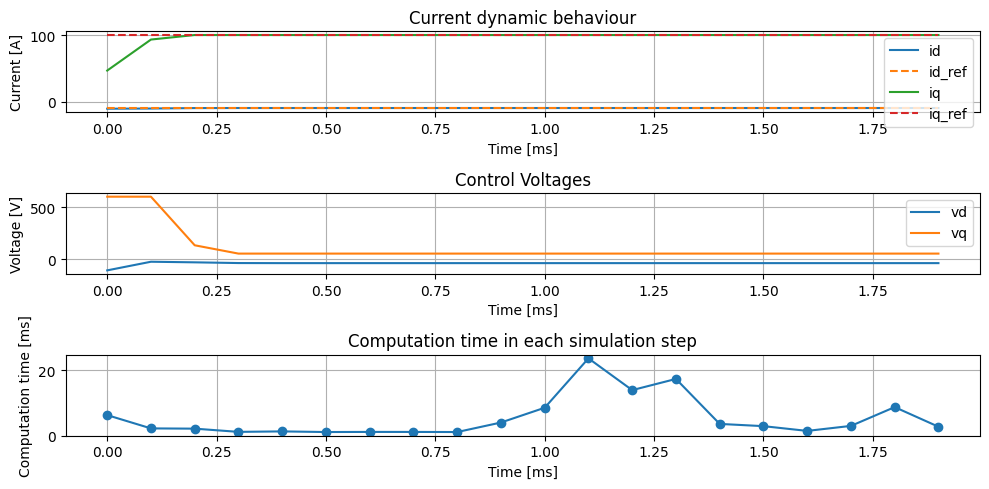

In [18]:
# Load the trained weights once
ddpg_controller = DDPG.load(os.path.join('weights', "DDPG_PMSM"), print_system_info=False)

def run_DDPG_controller_sim(envs=None, figsize=(10, 5), show=True):
    # Stable-Baselines3 works with its own vectorised copy of the environment, so `envs` is not used here
    vec_env = model.get_env()
    vec_env.seed(seed=0)
    table_data = run_simulation(envs=vec_env, controller=ddpg_controller, controller_type="SB3", metrics=metrics,
                                figsize=figsize, sim_steps=sim_plot_steps, plot=show)
    if show:
        show_table(table_data, ["DDPG"])
    return table_data

_ = run_DDPG_controller_sim()

**Questions – RL**
1. The agent never saw the motor equations. How did it learn which voltages to apply?
2. PI has an integrator and MPC an embedded one. Does the Actor have anything similar? How does that show in the steady-state error?
3. The reference is **not** part of the observation. Could this agent follow a different reference without retraining?
4. How does the computation time of DDPG compare with PI and MPC?

---
# 8. Comparison
The next cell runs all three controllers with the current slider settings and puts their metrics side by side.

In [19]:
table_data_PI   = run_pi_controller_sim(Kp=Kp_slider.value, Ki=Ki_slider.value, envs=env, anti_windup=aw_checkbox.value, show=False)
table_data_MPC  = run_mpc_controller_sim(Q=Q_slider.value, P=P_slider.value, R=R_slider.value, N=N_slider.value,
                                         envs=env, show=False)
table_data_DDPG = run_DDPG_controller_sim(show=False)

show_table([table_data_PI[0], table_data_MPC[0], table_data_DDPG[0]], ["PI", "MPC", "DDPG"])

**Discussion**
1. Which controller is best?
2. Which would you choose if:
   - the motor parameters are only roughly known?
   - it must run on a cheap microcontroller?
   - the current limits must never be exceeded?
3. What did each controller need before it could be used (tuning, a model, training data, training time)?

### Summary
- **PI**: simple, fast and reliable, but tuned by hand and not optimal.
- **MPC**: optimal and handles constraints, but needs an accurate model and more computation.
- **DDPG**: model-free and learns from interaction, but needs training, and its behaviour is harder to guarantee.

**Next session:** we look inside DDPG (Actor, Critic, replay buffer, exploration noise) and study what happens when the
measurements are **noisy**.